In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# SH wave parameters
eta_sh = 0.961827 #Ta 0.612514
etar_sh = 0.641531 #Ta 0.907069

# SV wave parameters
eta_sv_to_l = 0.084026 #Ta 0.213732
eta_sv_to_sv = 0.815352 #Ta 0.421423

# L wave parameters
eta_l_to_l = 0.904577 #Ta 0.570058
eta_l_to_sv = 0.074753 #Ta 0.085060

# SV/L wave parameters
etar_l_to_l = 0.310555 #Ta 0.530025
etar_l_to_sv = 0.063074 #Ta 0.216717
etar_sv_to_l = 0.015158 #Ta 0.053920
etar_sv_to_sv = 0.671113 #Ta 0.877578

# Averages
eta_l = eta_l_to_l + eta_l_to_sv
eta_t = 0.5*(eta_sh + eta_sv_to_l + eta_sv_to_sv)
etar_l = etar_l_to_l + etar_l_to_sv
etar_t = 0.5*(etar_sh + etar_sv_to_l + etar_sv_to_sv)

# Film parameters
tau = 242 #Ta 22
c_l = 6.65 #Ta 4.17 # * 10^5 cm/s
c_t = 3.26 #Al 2.08 # * 10^5 cm/s
mu_l = c_l * tau
mu_t = c_t * tau

In [3]:
def one_bounce(d):
    pabs_l = eta_l * (1 - np.exp(-4*d/mu_l))
    pabs_t = eta_t * (1 - np.exp(-4*d/mu_t))
    
    return pabs_l, pabs_t

In [4]:
def two_bounces(d):
    pabs_l = eta_l * (1 - np.exp(-4*d/mu_l)) * (1 + np.exp(-4*d/mu_l) * etar_l)
    pabs_t = eta_t * (1 - np.exp(-4*d/mu_t)) * (1 + np.exp(-4*d/mu_t) * etar_t)
    
    return pabs_l, pabs_t

In [5]:
def infinite_bounces(d):
    pabs_l = eta_l * (1 - np.exp(-4*d/mu_l)) / (1 - np.exp(-4*d/mu_l) * etar_l)
    pabs_t = eta_t * (1 - np.exp(-4*d/mu_t)) / (1 - np.exp(-4*d/mu_t) * etar_t)
    
    return pabs_l, pabs_t

In [6]:
def switching(d):
    pabs_sh = eta_sh * (1 - np.exp(-4*d/mu_t)) / (1 - np.exp(-4*d/mu_t) * etar_sh)

    outside_matrix = np.zeros((1, 2))
    outside_matrix[0,0] = 1 - np.exp(-4*d/mu_l)
    outside_matrix[0,1] = 1 - np.exp(-4*d/mu_t)

    bounce_matrix = np.zeros((2, 2))
    bounce_matrix[0,0] = etar_l_to_l * np.exp(-4*d/mu_l)
    bounce_matrix[0,1] = etar_sv_to_l * np.exp(-4*d/mu_t)
    bounce_matrix[1,0] = etar_l_to_sv * np.exp(-4*d/mu_l)
    bounce_matrix[1,1] = etar_sv_to_sv * np.exp(-4*d/mu_t)

    eigenvalues, S = np.linalg.eig(bounce_matrix)
    D = np.diag(1 / (1 - eigenvalues))
    Sinv = np.linalg.inv(S)

    l_sv_matrix = np.zeros((2, 2))
    l_sv_matrix[0,0] = eta_l_to_l
    l_sv_matrix[0,1] = eta_sv_to_l
    l_sv_matrix[1,0] = eta_l_to_sv
    l_sv_matrix[1,1] = eta_sv_to_sv

    prod = outside_matrix @ S @ D @ Sinv @ l_sv_matrix
    pabs_l = prod[0,0]
    pabs_sv = prod[0,1]
    pabs_t = 0.5*(pabs_sh + pabs_sv)

    return pabs_l, pabs_t

In [14]:
thicknesses = np.linspace(0, 1000, num=1001)
pabs_l1 = np.array([one_bounce(d)[0] for d in thicknesses])
pabs_l2 = np.array([two_bounces(d)[0] for d in thicknesses])
pabs_l3 = np.array([infinite_bounces(d)[0] for d in thicknesses])
pabs_l4 = np.array([switching(d)[0] for d in thicknesses])

pabs_t1 = np.array([one_bounce(d)[1] for d in thicknesses])
pabs_t2 = np.array([two_bounces(d)[1] for d in thicknesses])
pabs_t3 = np.array([infinite_bounces(d)[1] for d in thicknesses])
pabs_t4 = np.array([switching(d)[1] for d in thicknesses])

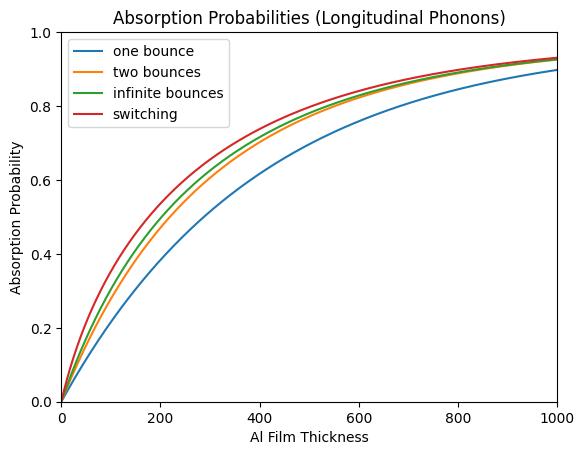

In [15]:
plt.plot(thicknesses, pabs_l1, label='one bounce')
plt.plot(thicknesses, pabs_l2, label='two bounces')
plt.plot(thicknesses, pabs_l3, label='infinite bounces')
plt.plot(thicknesses, pabs_l4, label='switching')

plt.title('Absorption Probabilities (Longitudinal Phonons)')
plt.xlabel('Al Film Thickness')
plt.ylabel('Absorption Probability')
plt.xlim(0, 1000)
plt.ylim(0, 1)

plt.legend()
plt.show()

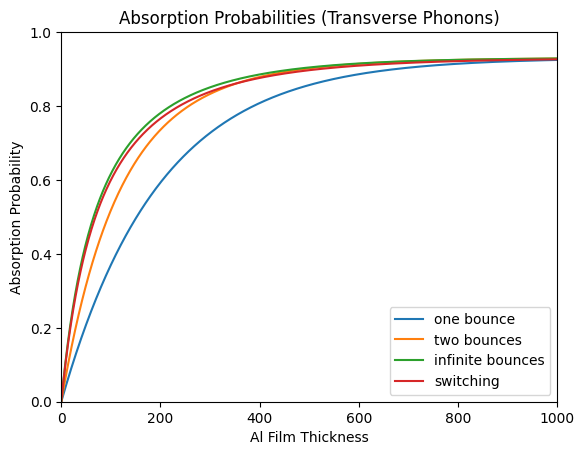

In [16]:
plt.plot(thicknesses, pabs_t1, label='one bounce')
plt.plot(thicknesses, pabs_t2, label='two bounces')
plt.plot(thicknesses, pabs_t3, label='infinite bounces')
plt.plot(thicknesses, pabs_t4, label='switching')

plt.title('Absorption Probabilities (Transverse Phonons)')
plt.xlabel('Al Film Thickness')
plt.ylabel('Absorption Probability')
plt.xlim(0, 1000)
plt.ylim(0, 1)

plt.legend()
plt.show()